<a href="https://colab.research.google.com/github/AlbertBaby/AlbertBaby.github.io/blob/main/assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

In [2]:
df = pd.read_csv("diabetes.csv")

df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
print("Dataset Shape:", df.shape)
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Dataset Shape: (768, 9)
Number of Rows: 768
Number of Columns: 9


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [7]:
print(df.isnull().sum())

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [8]:
print("Total Missing Values:", df.isnull().sum().sum())

Total Missing Values: 0


In [9]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [10]:
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (768, 8)
Target Shape: (768,)


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)

print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Training Features Shape: (614, 8)
Testing Features Shape: (154, 8)
Training Target Shape: (614,)
Testing Target Shape: (154,)


In [12]:
zero_missing_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

df[zero_missing_columns] = df[zero_missing_columns].replace(0, np.nan)



Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [14]:
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [15]:
imputer = SimpleImputer(strategy="median")

X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("Missing values in training data:", X_train.isnull().sum().sum())
print("Missing values in testing data:", X_test.isnull().sum().sum())

Missing values in training data: 0
Missing values in testing data: 0


In [16]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled Training Data Shape:", X_train_scaled.shape)
print("Scaled Testing Data Shape:", X_test_scaled.shape)

Scaled Training Data Shape: (614, 8)
Scaled Testing Data Shape: (154, 8)


In [18]:
print("\nTraining Dataset Size:", X_train_scaled.shape)
print("Testing Dataset Size:", X_test_scaled.shape)

print("\nTraining Samples:", len(y_train))
print("Testing Samples:", len(y_test))

print("\nMissing Values After Preprocessing:")
print("Training:", np.isnan(X_train_scaled).sum())
print("Testing:", np.isnan(X_test_scaled).sum())


Training Dataset Size: (614, 8)
Testing Dataset Size: (154, 8)

Training Samples: 614
Testing Samples: 154

Missing Values After Preprocessing:
Training: 0
Testing: 0


In [19]:
# Part 2

In [20]:
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt
import seaborn as sns

In [21]:
model = LogisticRegression(random_state=42)


In [22]:
model.fit(X_train_scaled, y_train)

LogisticRegression(random_state=42)

In [23]:
# Predictions on training data
y_train_pred = model.predict(X_train_scaled)

# Predictions on testing data
y_test_pred = model.predict(X_test_scaled)


In [24]:
print("Actual values:", y_test.values[:10])
print("Predicted values:", y_test_pred[:10])

Actual values: [0 0 0 1 0 0 1 1 0 0]
Predicted values: [1 0 0 0 0 0 0 1 0 1]


In [25]:
train_accuracy = accuracy_score(y_train, y_train_pred)

print("Training Accuracy:", round(train_accuracy * 100, 2), "%")

Training Accuracy: 79.64 %


In [26]:
test_accuracy = accuracy_score(y_test, y_test_pred)

print("Testing Accuracy:", round(test_accuracy * 100, 2), "%")

Testing Accuracy: 70.78 %


In [27]:
precision = precision_score(y_test, y_test_pred)
recall = recall_score(y_test, y_test_pred)
f1 = f1_score(y_test, y_test_pred)

print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-Score:", round(f1, 4))

Precision: 0.6
Recall: 0.5
F1-Score: 0.5455


In [28]:
print("Classification Report:\n")

print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=["No Diabetes", "Diabetes"]
    )
)

Classification Report:

              precision    recall  f1-score   support

 No Diabetes       0.75      0.82      0.78       100
    Diabetes       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154



In [29]:
cm = confusion_matrix(y_test, y_test_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[82 18]
 [27 27]]


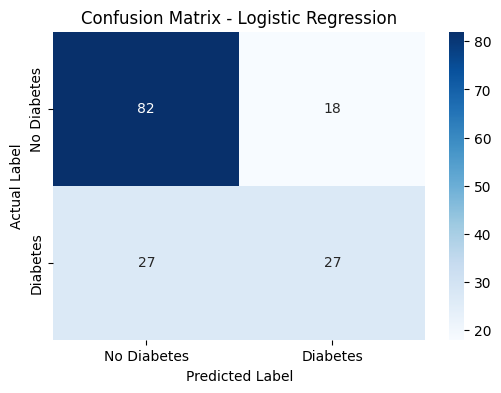

In [30]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Diabetes", "Diabetes"],
    yticklabels=["No Diabetes", "Diabetes"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Logistic Regression")

plt.show()

In [31]:
performance_comparison = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "Accuracy": [
        train_accuracy,
        test_accuracy
    ]
})

performance_comparison["Accuracy (%)"] = (
    performance_comparison["Accuracy"] * 100
)

performance_comparison

,Dataset,Accuracy,Accuracy (%)
0,Training,0.796417,79.641694
1,Testing,0.707792,70.779221


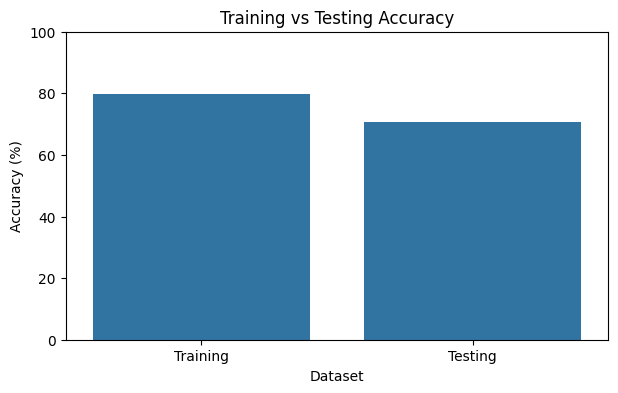

In [32]:
plt.figure(figsize=(7, 4))

sns.barplot(
    data=performance_comparison,
    x="Dataset",
    y="Accuracy (%)"
)

plt.title("Training vs Testing Accuracy")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

plt.show()

In [33]:
results = pd.DataFrame({
    "Metric": [
        "Training Accuracy",
        "Testing Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ],
    "Score": [
        train_accuracy,
        test_accuracy,
        precision,
        recall,
        f1
    ]
})

results["Score (%)"] = results["Score"] * 100

print("Model Performance Analysis")
display(results)

Model Performance Analysis


,Metric,Score,Score (%)
0,Training Accuracy,0.796417,79.641694
1,Testing Accuracy,0.707792,70.779221
2,Precision,0.600000,60.000000
3,Recall,0.500000,50.000000
4,F1-Score,0.545455,54.545455
